# Project 1 – Reliability & Maintenance Analytics – walkthrough
This notebook runs the 8 project scripts in order and shows the key results inline.
Each script can also be run on its own from the project folder: `python src/0X_....py`.

**Business questions:** How reliable is each machine? Where does downtime come from? Do alarms warn early enough? Can sensor data predict failures?

In [1]:
# Setup - run this cell first (the notebook lives in notebooks/, the scripts in src/)
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

SRC = Path("../src").resolve()
sys.path.insert(0, str(SRC))            # must come BEFORE importing style / config

from style import apply_style
apply_style()

FIG = Path("../reports/figures")
PROC = Path("../data/processed")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def show(*names):
    """Display saved figures by file name (without .png)."""
    for name in names:
        display(Image(filename=FIG / f"{name}.png"))

## Step 1 – Data cleaning
The PI historian writes text (`I/O Timeout`, `Bad Input`, `Calc Failed`…) into numeric columns, instruments spike or freeze, and the legend had two wrong tag descriptions. We **flag** problems and keep an audit trail rather than silently deleting data.
Domain rule used: a sudden change during a trip or start-up is real process behaviour, so spikes are only flagged when the machine state was stable.

In [2]:
%run ../src/01_data_cleaning.py

STEP 1 - Data cleaning
  sensor rows: 26,304 | columns: 73 | 2023-01-01 00:00:00 -> 2025-12-31 23:00:00
  events: 98 | alarms: 382
  flagged values: 5,262 of 1,762,368 (0.30 %)
  flags by type: {'I/O Timeout': 1742, 'Calc Failed': 1351, 'No Data': 1316, 'Spike': 269, 'Shutdown': 268, 'Bad Input': 165, 'Frozen value': 139, 'Out of physical range': 12}
  saved cleaned files to C:\Users\irace\OneDrive\Documentos\GitHub\OGP1_project_A\Projecto_1\data\processed


In [3]:
pd.read_csv(PROC / "data_quality_summary.csv").sort_values("pct_good").head(8)

,tag,Bad Input,Calc Failed,Frozen value,I/O Timeout,No Data,Out of physical range,Shutdown,Spike,total_flagged,pct_good
16,OGP1.K101_EFF_POLY,0,1351,0,26,0,1,4,3,1385,94.73
28,OGP1.K101_SURGE_MARGIN,0,0,0,26,1316,0,4,7,1353,94.86
18,OGP1.K101_VT1010B,55,0,0,26,0,0,4,6,91,99.65
44,OGP1.E401_FT4006,0,0,55,26,0,0,4,4,89,99.66
43,OGP1.E401_PDT4005,1,0,55,26,0,0,4,2,88,99.67
63,OGP1.P201B_TT5012,1,0,0,26,0,0,4,48,79,99.70
4,OGP1.V301_LT3003,2,0,29,26,0,1,4,5,67,99.75
58,OGP1.P201B_PT5002,3,0,0,26,0,0,4,15,48,99.82


## Step 2 – SQL database and KPI queries
Star schema in SQLite (`dim_asset`, `dim_tag`, `fact_sensor_hourly`, `fact_run_status`, `fact_event`, `fact_alarm`) and 12 KPI queries in `sql/02_kpi_queries.sql`.

In [4]:
%run ../src/02_load_sql.py

STEP 2 - Load SQL database and run KPI queries

--- q01_table_row_counts (6 rows) ---
        table_name  n_rows
         dim_asset      12
           dim_tag      72
fact_sensor_hourly 1758510
   fact_run_status  105216
        fact_event      98
        fact_alarm     382

--- q02_operating_hours_by_status (4 rows) ---
asset_id  running_h  stopped_standby_h  maintenance_h  tripped_h  unknown_h  calendar_h
  GT-101      24993                  2           1220         59         30       26304
   K-101      24993                  2           1220         59         30       26304
  P-201A      13027              11854           1376         17         30       26304
  P-201B      12915              12541            798         20         30       26304

--- q03_reliability_kpis (4 rows) ---
asset_id        equipment_class criticality  running_h  n_failures  n_unplanned_events  mtbf_h  mttr_h  availability_pct  inherent_availability_pct
  P-201B       Centrifugal pump           B      1

## Step 3 – Reliability analysis
MTBF, MTTR, availability, Pareto, Weibull and the gap between the P-F interval and the first DCS alarm.

In [5]:
%run ../src/03_reliability_analysis.py

STEP 3 - Reliability analysis
asset_id  running_h  n_failures  mtbf_h  mtbf_days  mttr_h  availability_pct  failure_downtime_h
   K-101      24993          10    2499      104.1    53.6             95.14                 536
  GT-101      24993           4    6248      260.3    59.0             95.14                 236
  P-201A      13027           5    2605      108.6    43.6             94.70                 218
  P-201B      12915           6    2152       89.7    44.2             96.89                 265
  P-201A/B system availability (1-out-of-2): 98.63 %
                            group  n_failures  n_censored  beta_shape  eta_scale_h                                    pattern  reliability_30d_running  B10_life_h
                 Pumps (P-201A/B)          11           2        1.27         2497         wear-out (increasing failure rate)                    0.814         426
Compressor train (K-101 + GT-101)          14           2        0.80         3291 infant mortality (decre

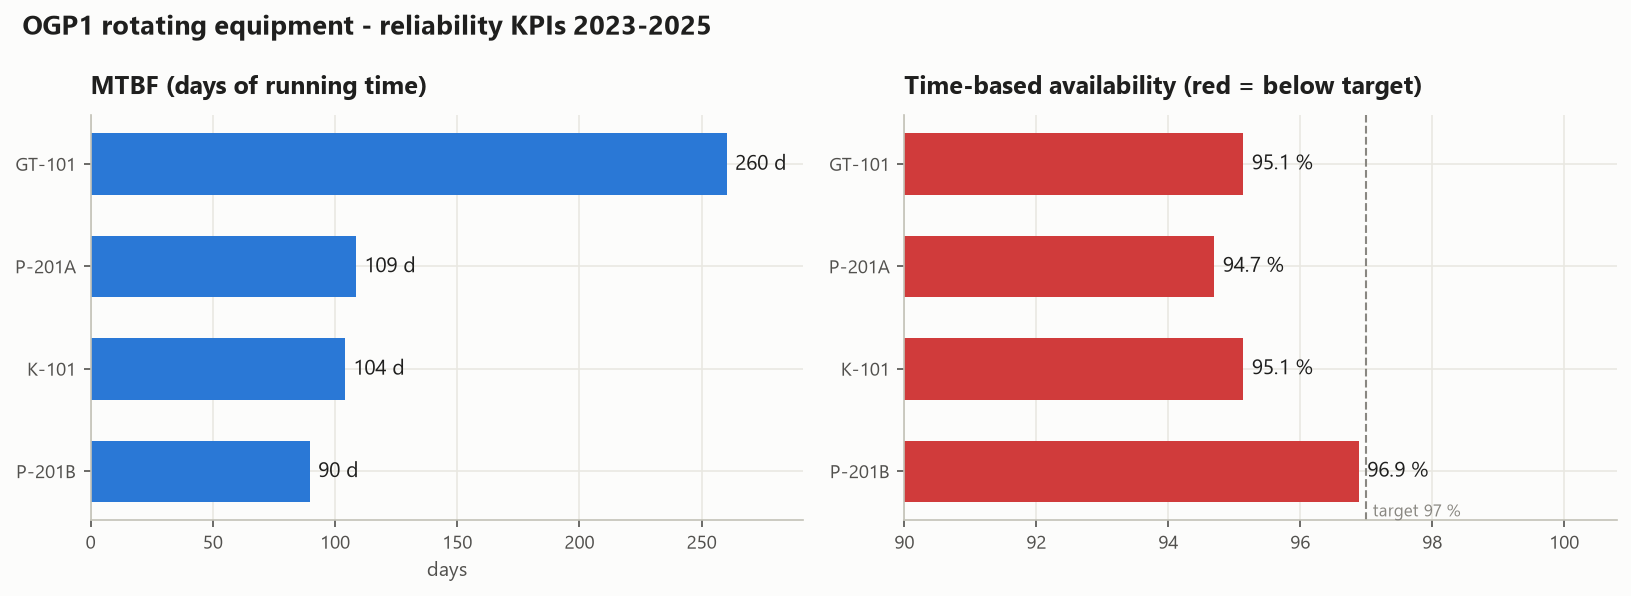

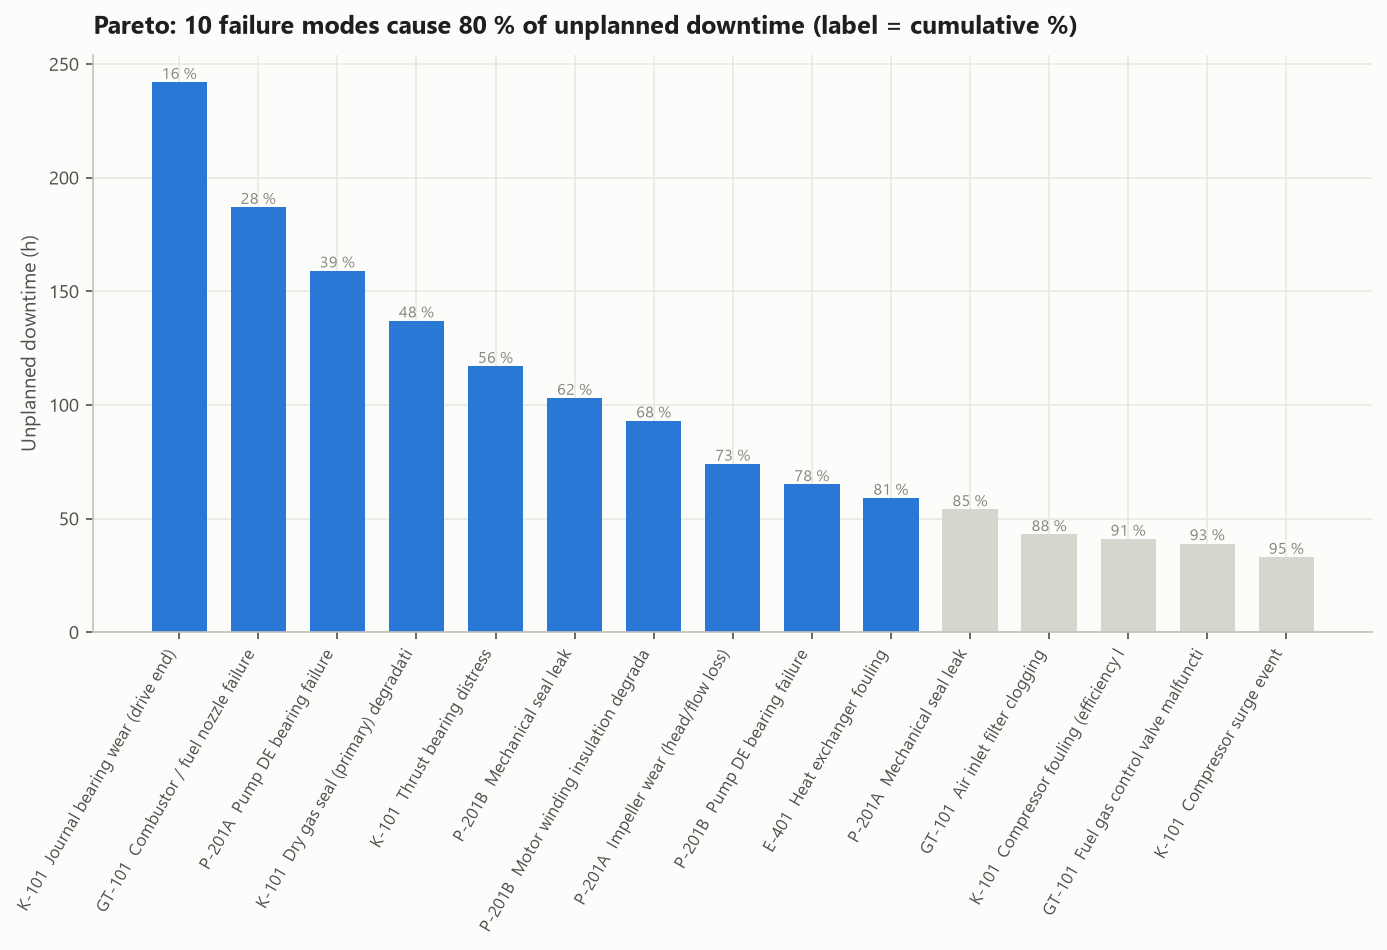

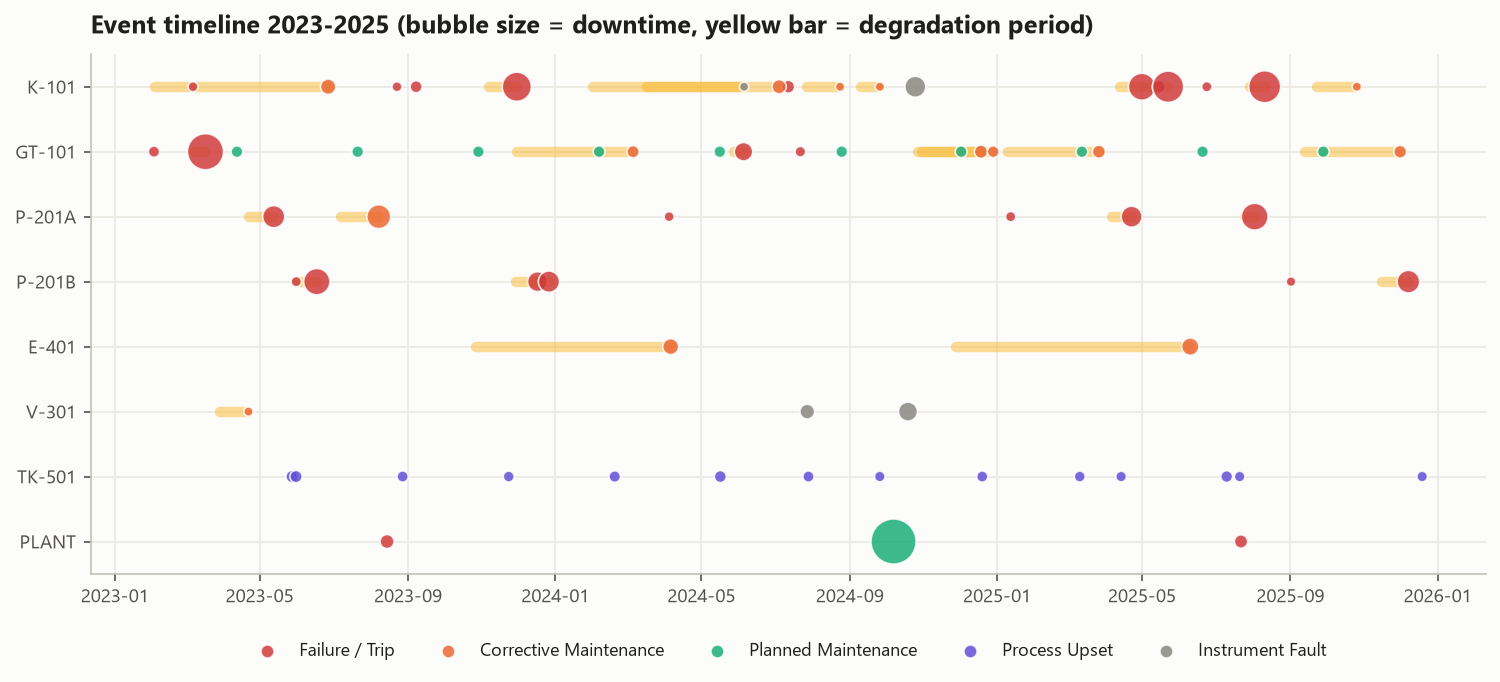

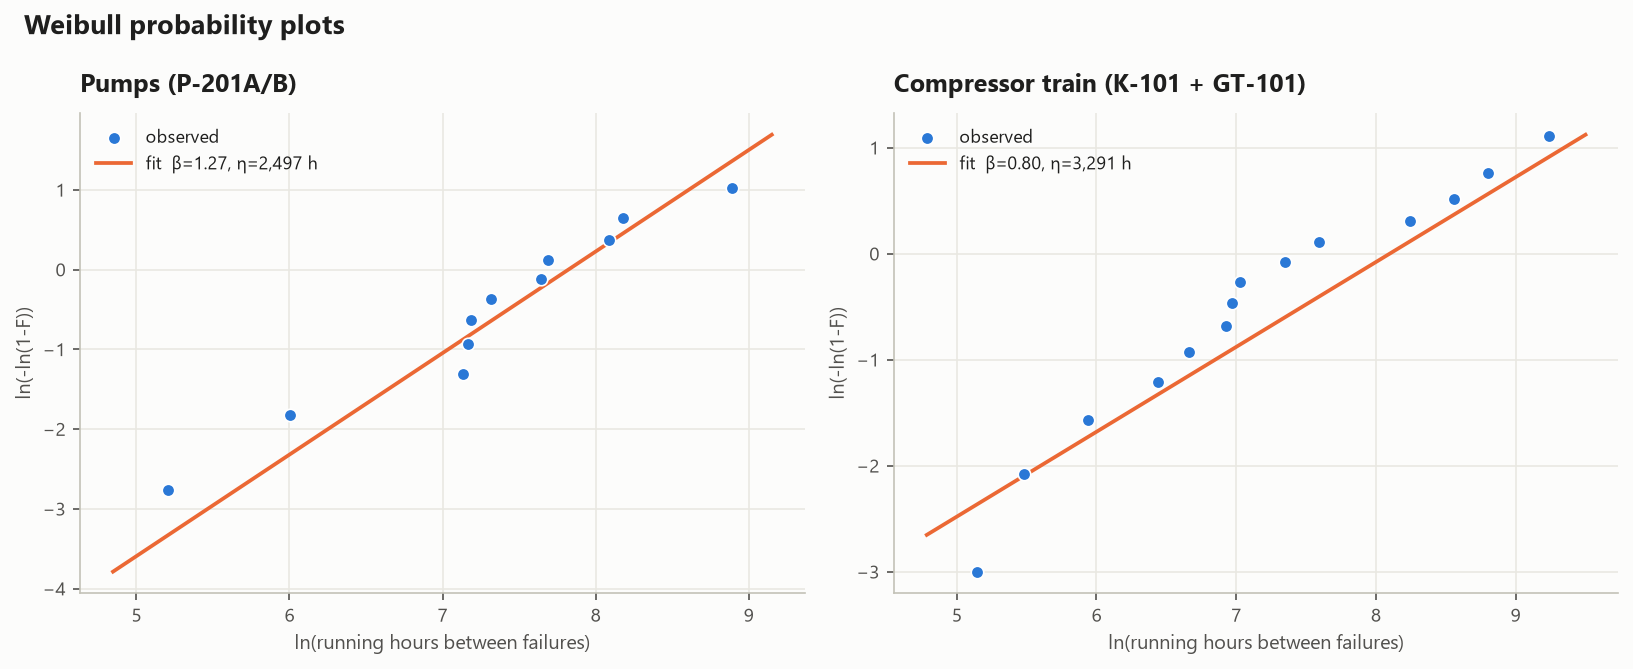

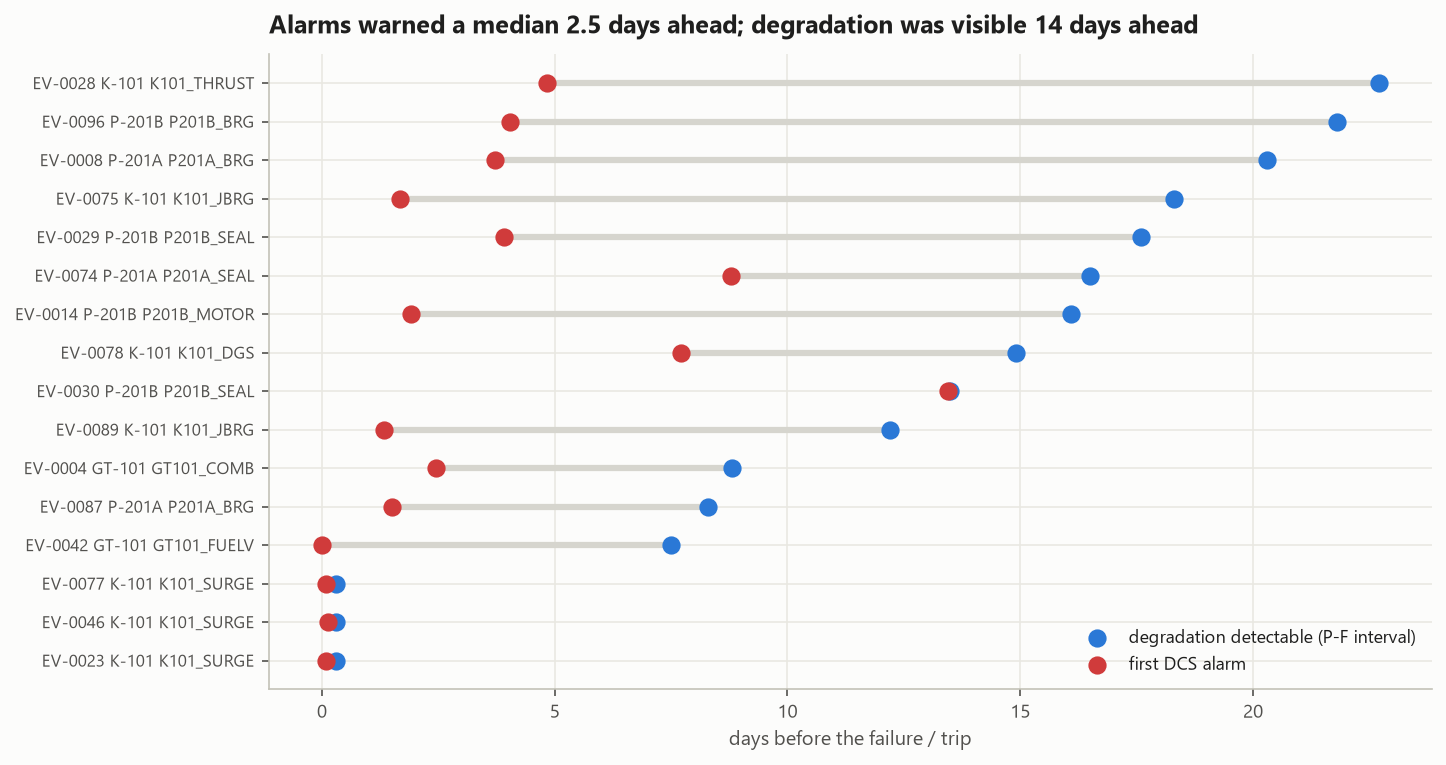

In [6]:
show("fig01_mtbf_availability", "fig02_downtime_pareto", "fig03_event_timeline",
     "fig04_weibull", "fig05_warning_time_gap")

**Reading the Weibull results:** β > 1 for the pumps = wear-out → condition-based replacement pays off. β < 1 for the compressor train = early-life / random failures (spurious trips, surge) → fixing root causes beats shorter PM intervals.

## Step 4 – Alarm management (ISA-18.2 / EEMUA 191)

In [7]:
%run ../src/04_alarm_analysis.py

STEP 4 - Alarm analysis
  total_alarms                 382
  avg_alarms_per_day           0.35
  max_alarms_per_day           9
  standing_alarms_24h_plus     71
  pct_standing                 18.6
  pct_high_priority            19.4
  pct_top10_tags               83.8
  pct_linked_to_event          98.7
  pct_repeat_within_24h        43.7
                   Tag                                Descriptor  n  standing  repeats  linked  avg_dur
       OGP1.FLR_FT6001                            Flare gas flow 66        14        0    0.98    30.85
    OGP1.K101_EFF_POLY Polytropic efficiency (PI AF calculation) 61         5       57    1.00    18.43
      OGP1.E401_TT4002       Crude outlet temperature (hot side) 57         7       50    1.00    24.93
     OGP1.E401_PDT4005          Crude side differential pressure 44        18       34    1.00    47.18
     OGP1.TK501_LT5101                  Crude storage tank level 20         0        0    1.00     7.80
     OGP1.P201B_PT5001            

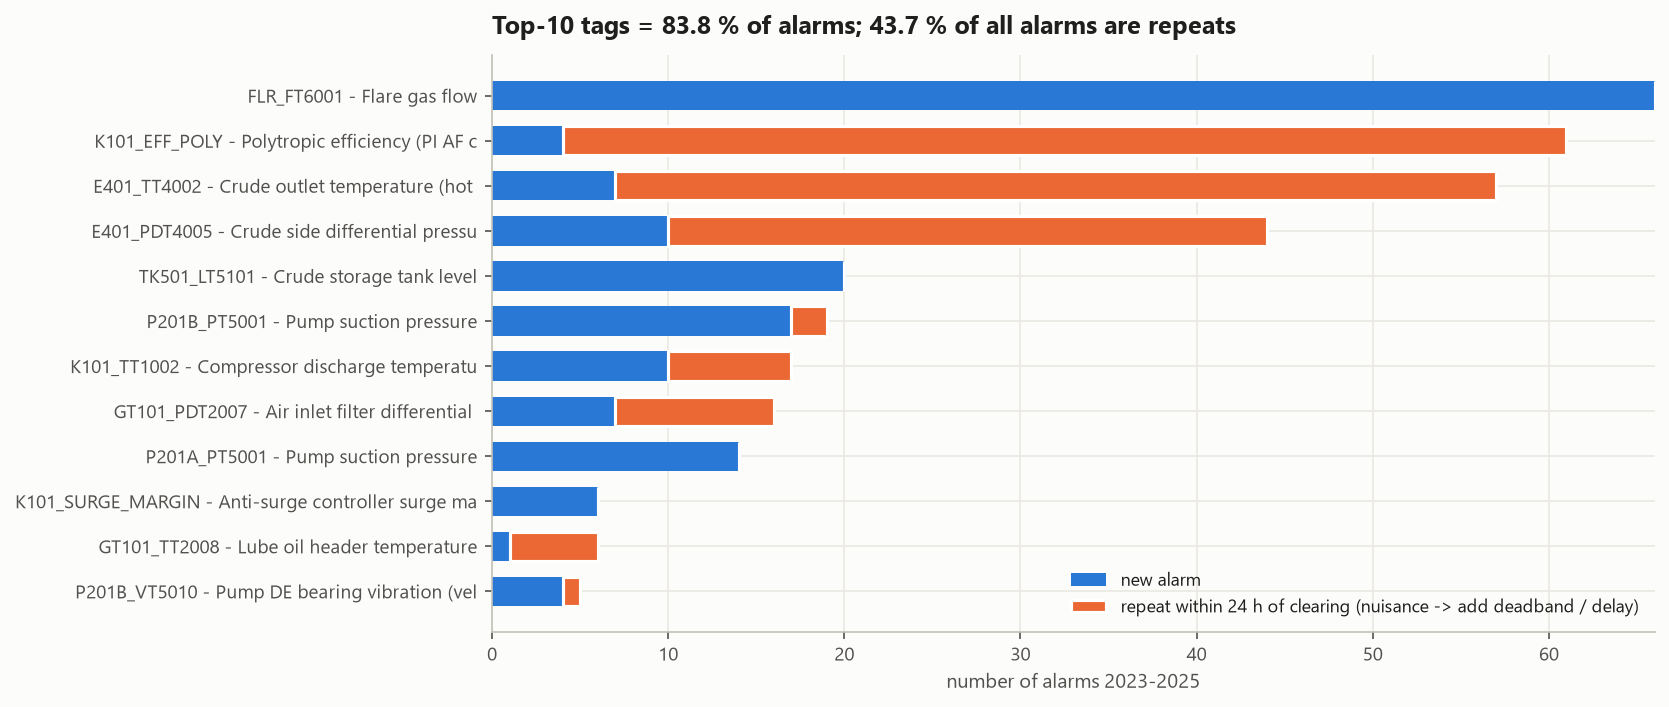

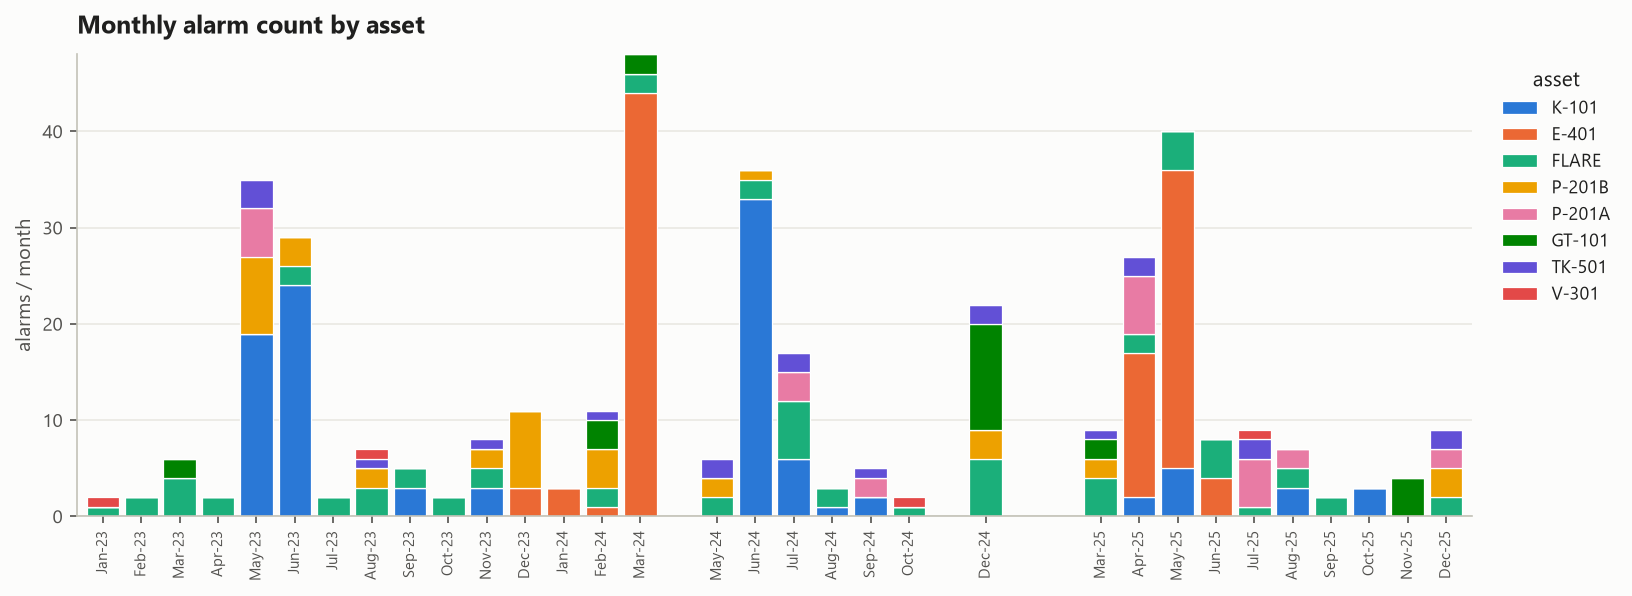

In [8]:
show("fig06_alarm_bad_actors", "fig07_alarm_trend")

## Step 5 – Condition monitoring EDA: what does degradation look like?

In [9]:
%run ../src/05_condition_monitoring_eda.py

STEP 5 - Condition monitoring EDA
  figures saved


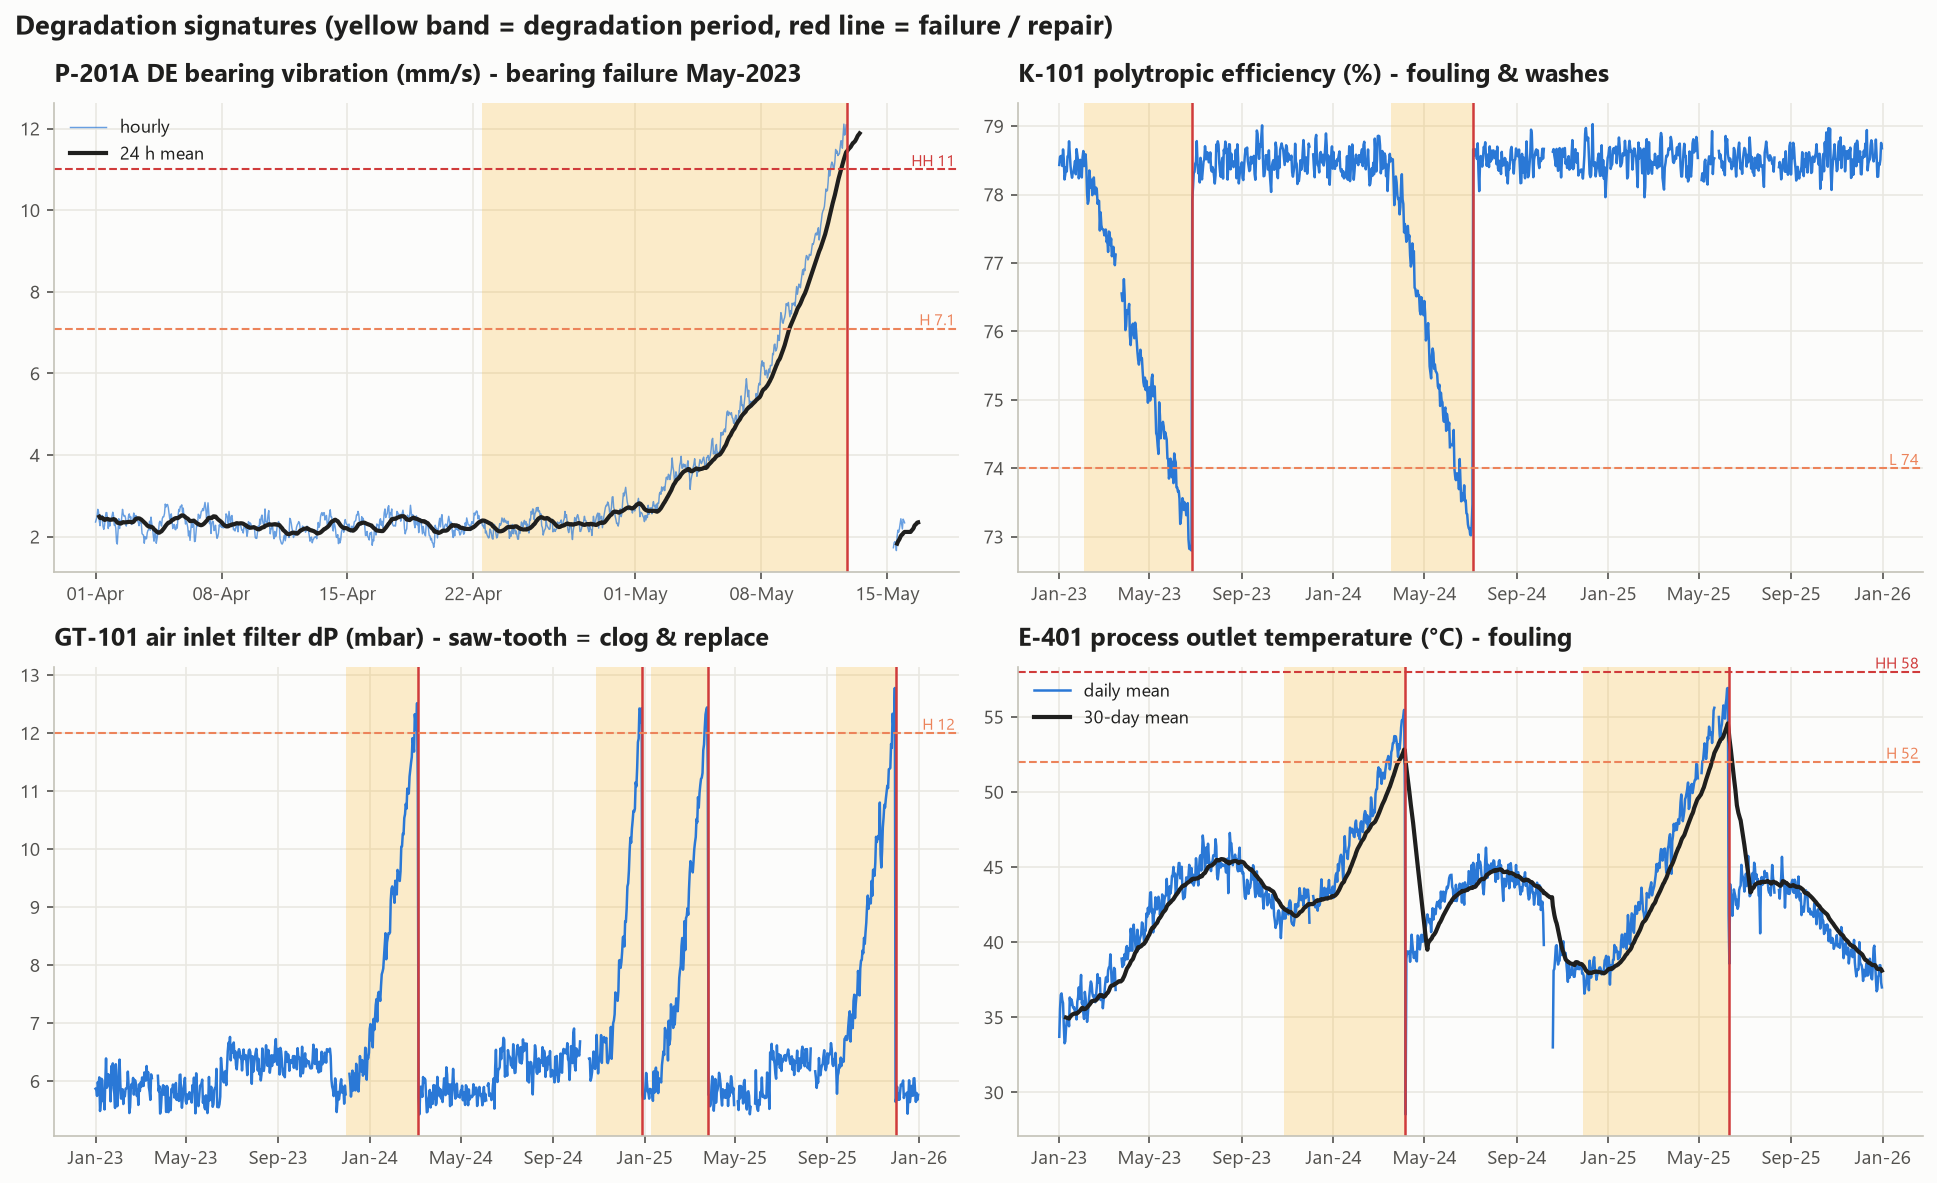

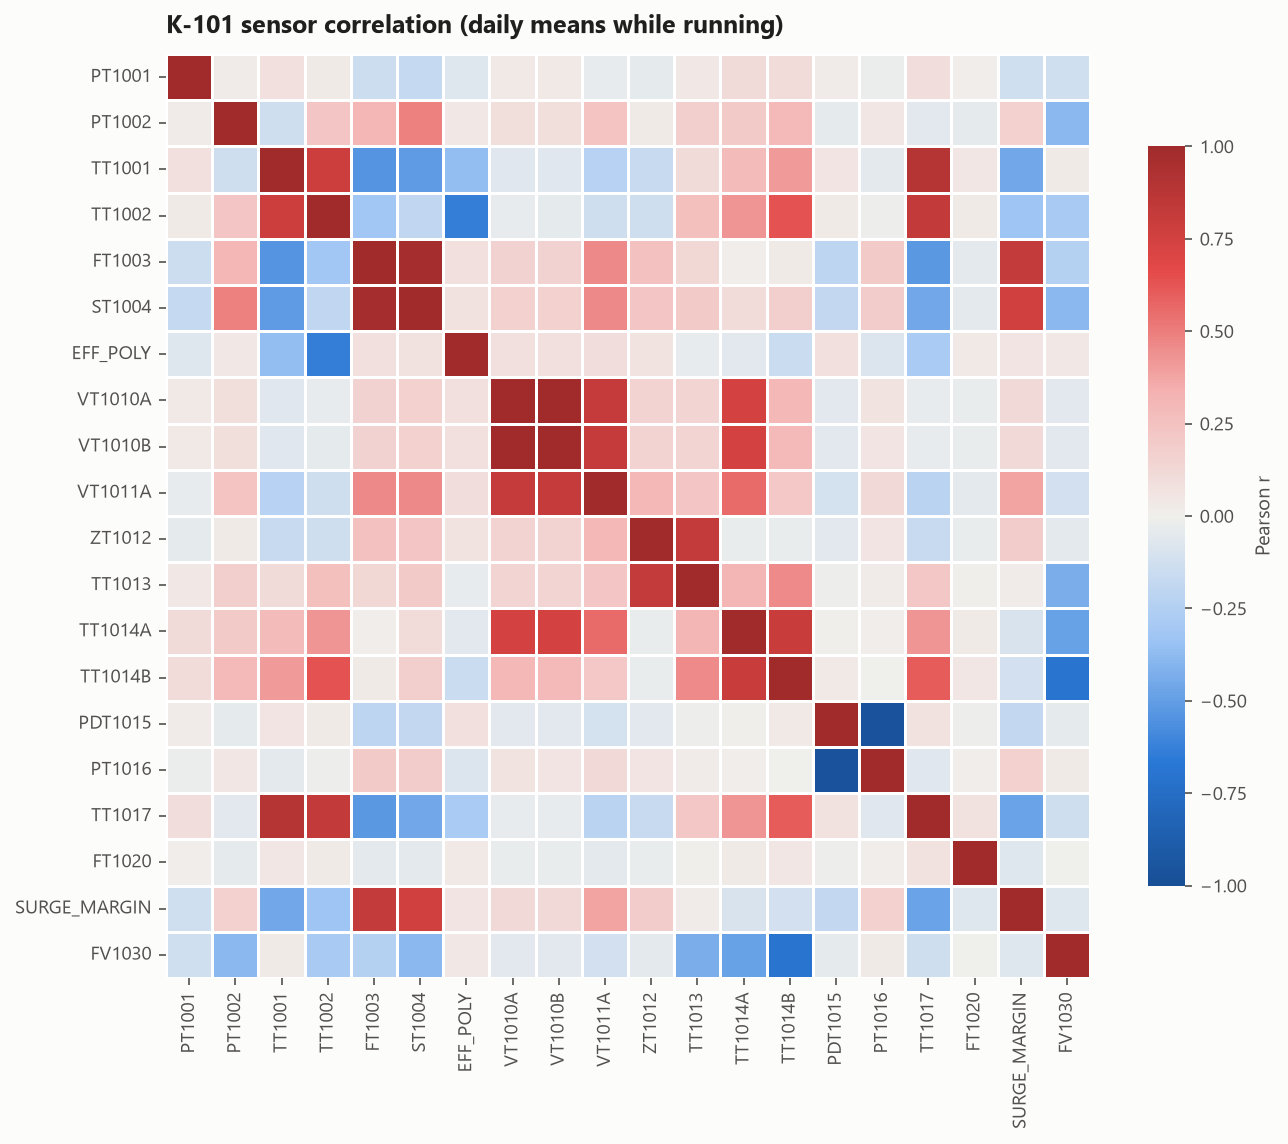

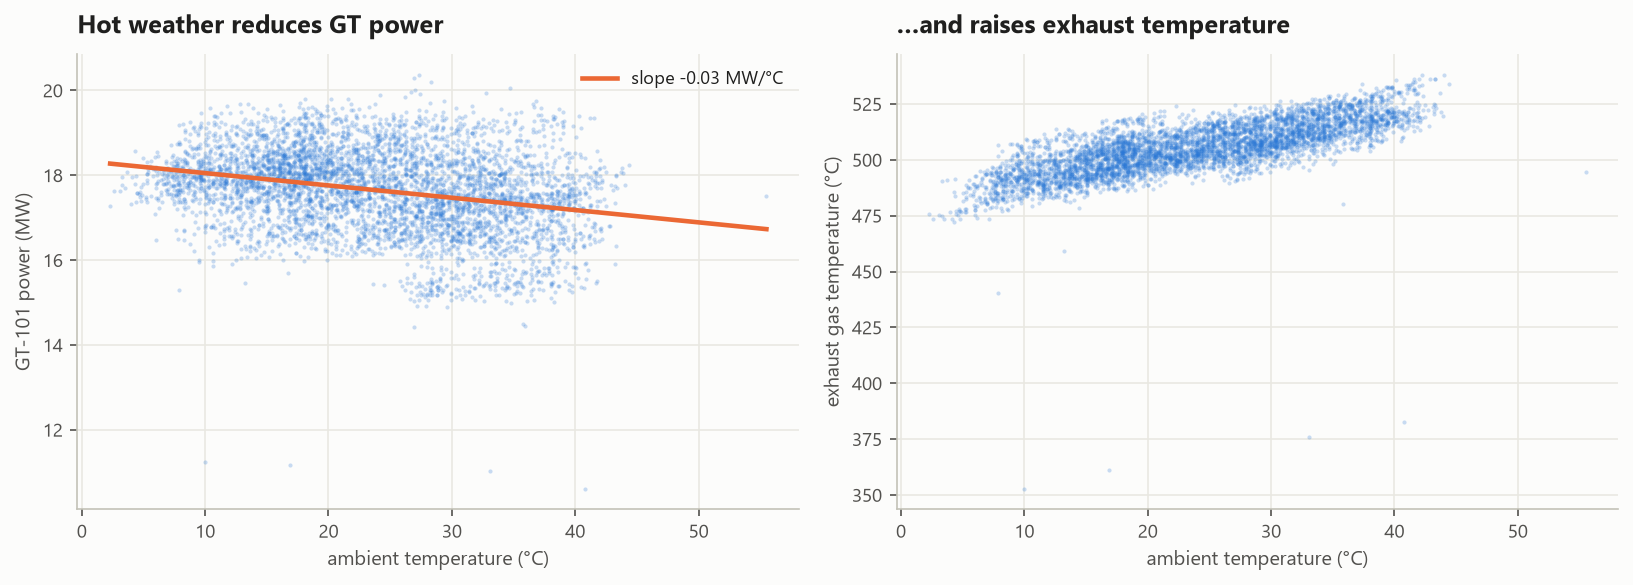

In [10]:
show("fig08_degradation_signatures", "fig09_k101_correlation", "fig10_ambient_effect")

## Step 6 – Failure prediction
**Layer A – normal-behaviour model (unsupervised):** for every condition sensor, predict what it *should* read from the operating context (ambient, flow, speed, suction pressure), trained on healthy 2023-2024 hours only. Residual z-scores → **health index**.

**Layer B – supervised classifier:** gradient boosting on residual features, target = inside the P-F interval.

**Honest validation:** train 2023-2024, test on 2025 (future data the model never saw).

In [11]:
%run ../src/06_failure_prediction.py

STEP 6 - Failure prediction
  P-201A        normal-behaviour models: 8 sensors | healthy training hours: 7,279
  P-201B        normal-behaviour models: 8 sensors | healthy training hours: 7,512
  K-101/GT-101  normal-behaviour models: 26 sensors | healthy training hours: 5,514

  TEST YEAR 2025 - hour-level performance
     group                       method  precision  recall    f1  roc_auc  pr_auc  healthy_hours_in_alert_pct  false_alert_episodes
     pumps  Health index (unsupervised)      0.773   0.633 0.696    0.837   0.740                        2.77                    18
     pumps   ML classifier (supervised)      0.820   0.558 0.664    0.879   0.752                        1.82                     5
     pumps DCS alarm (current practice)      0.817   0.196 0.316    0.595   0.264                        0.65                     4
compressor  Health index (unsupervised)      0.999   0.392 0.563    0.857   0.915                        0.06                     0
compressor   ML cla

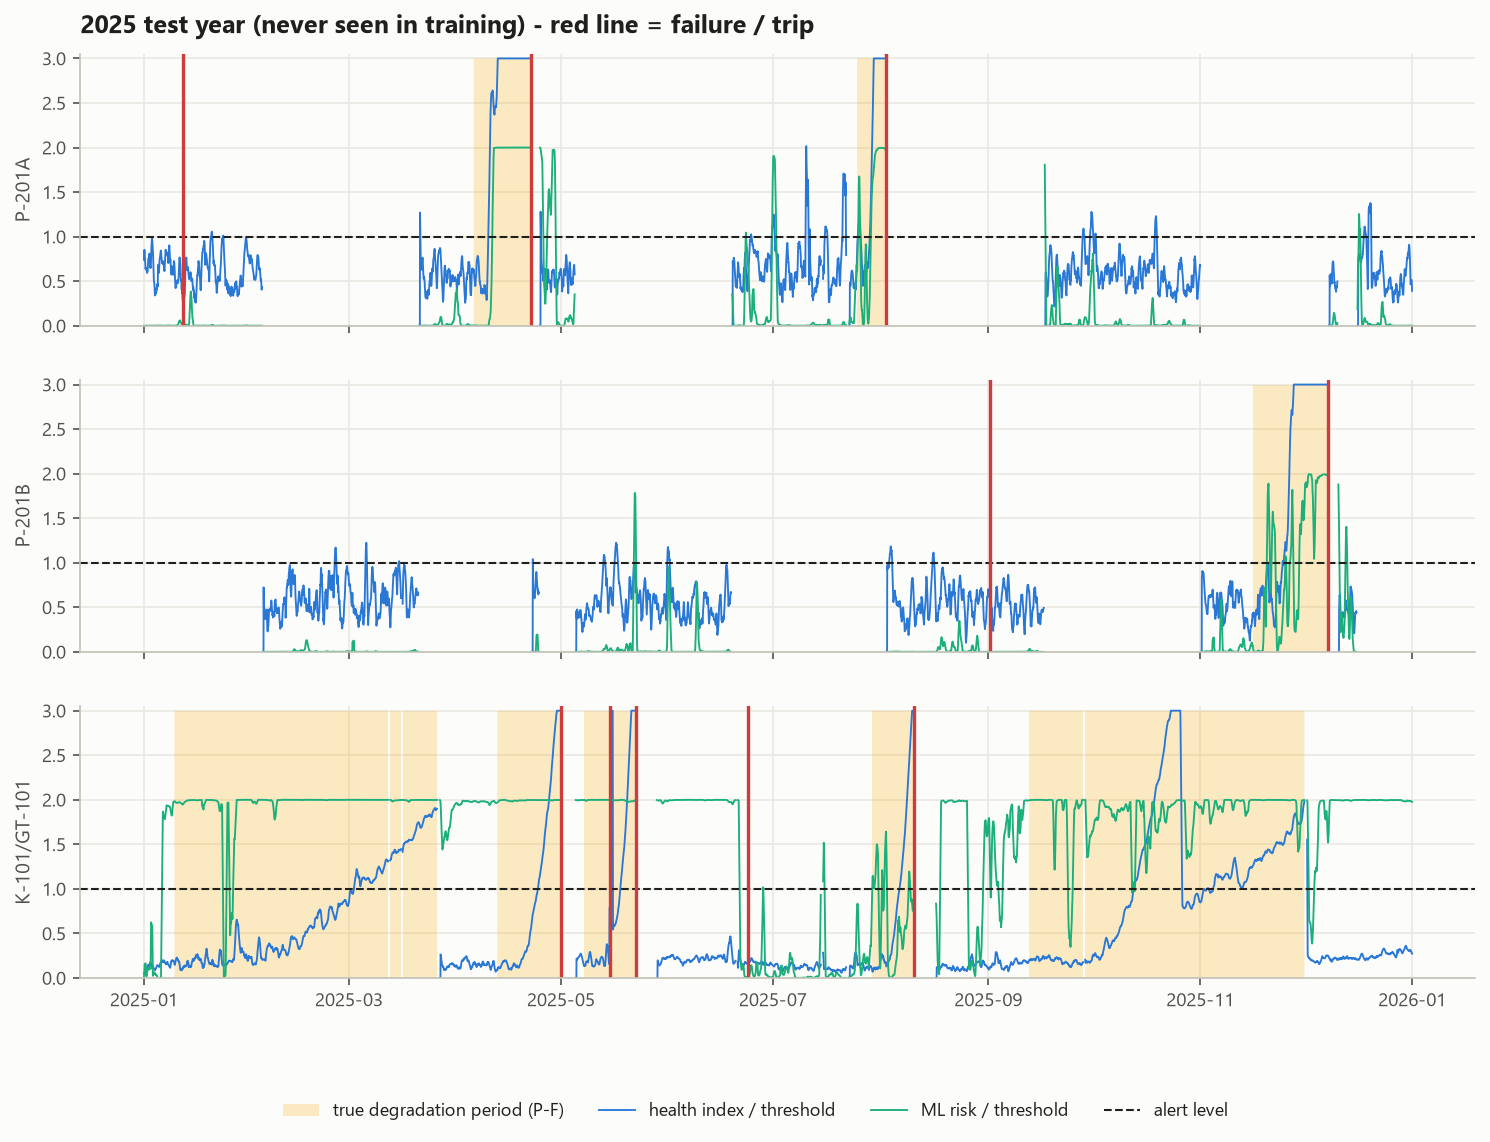

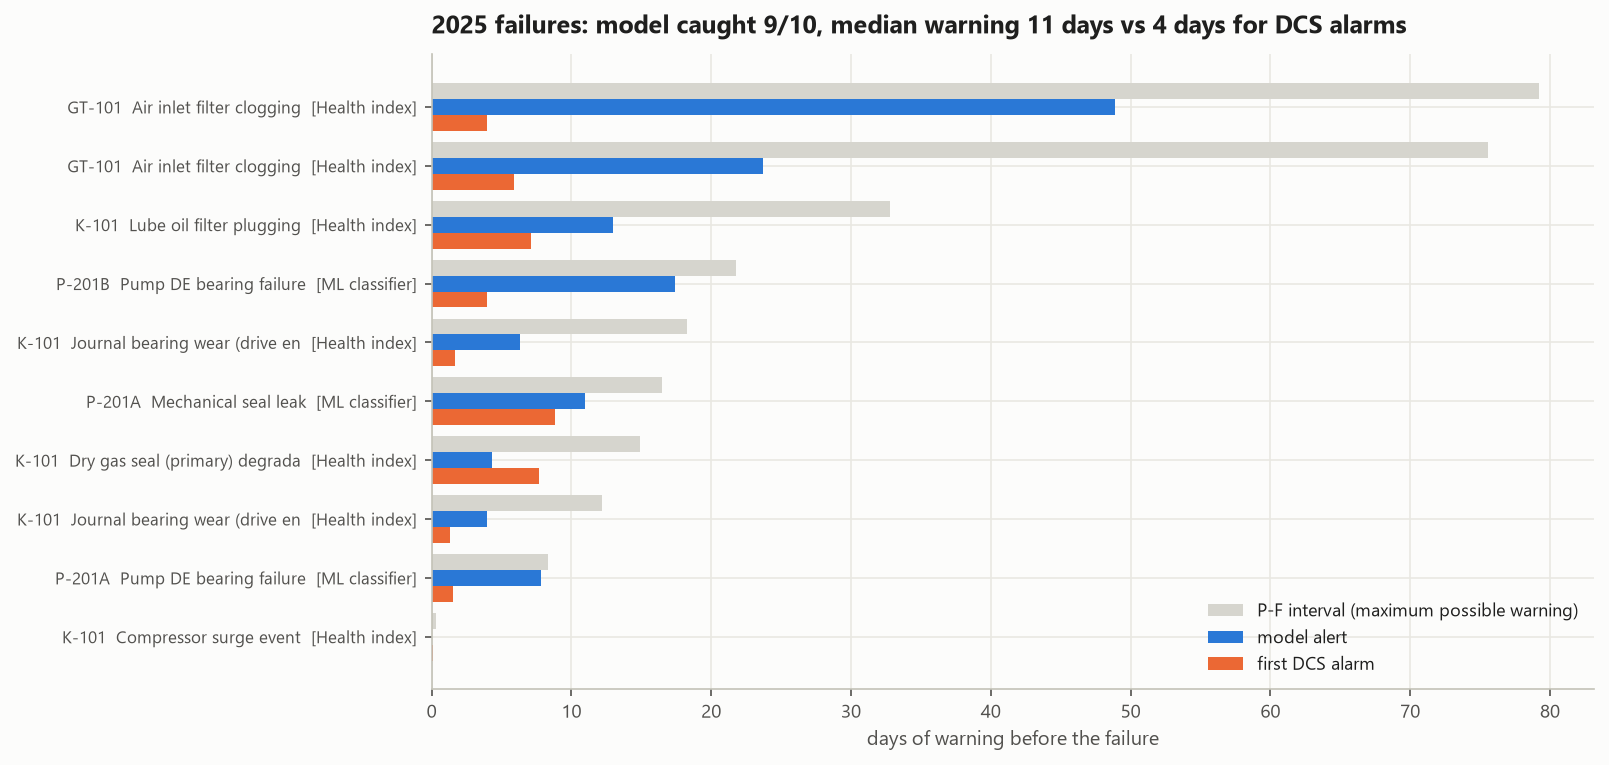

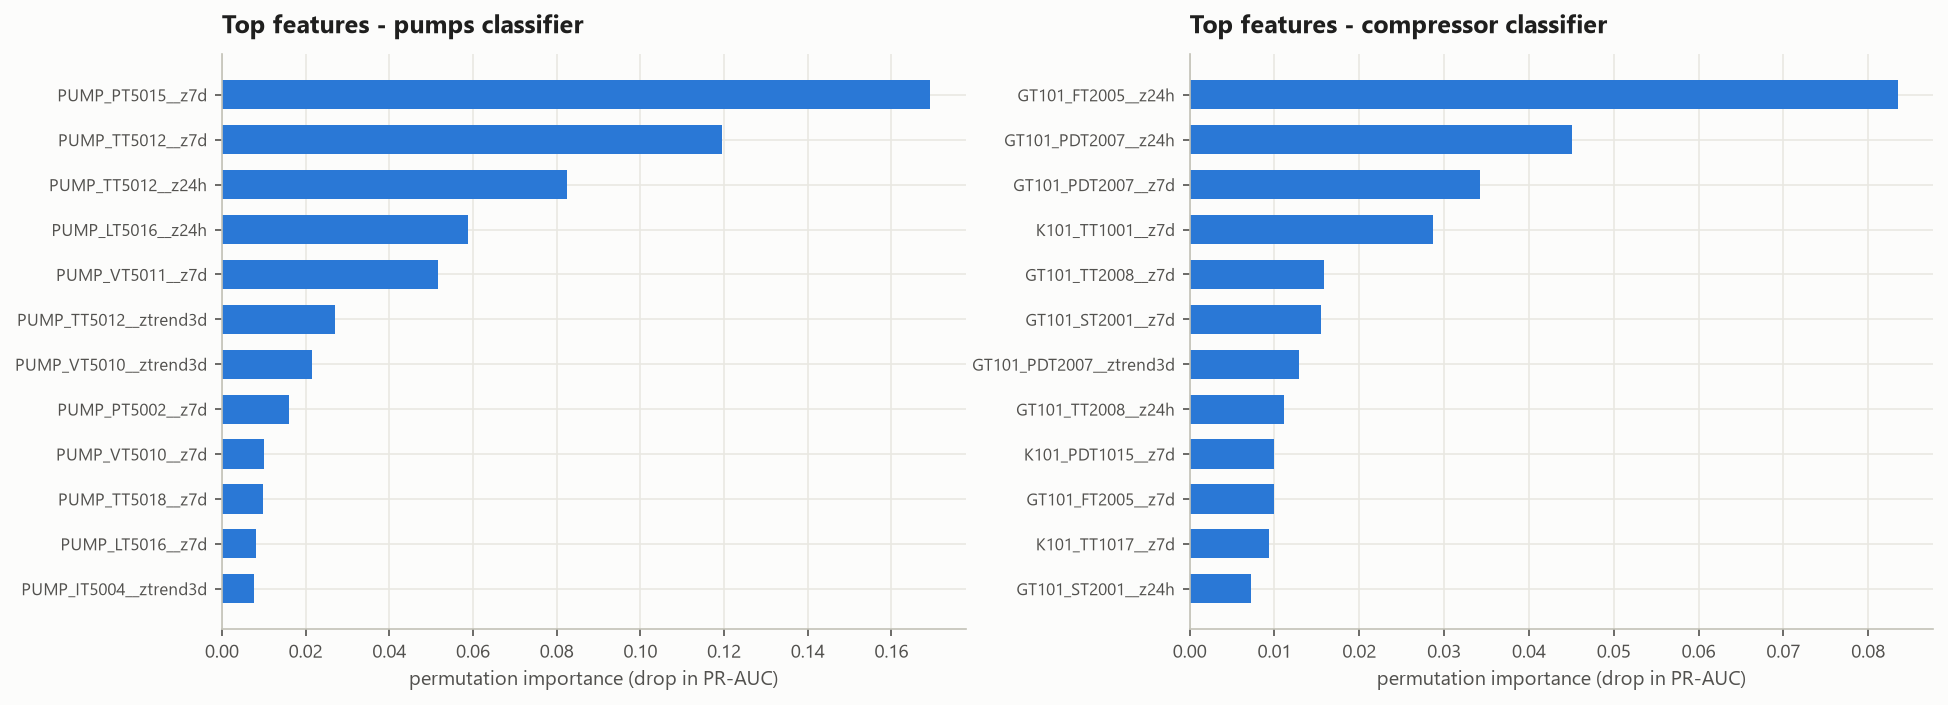

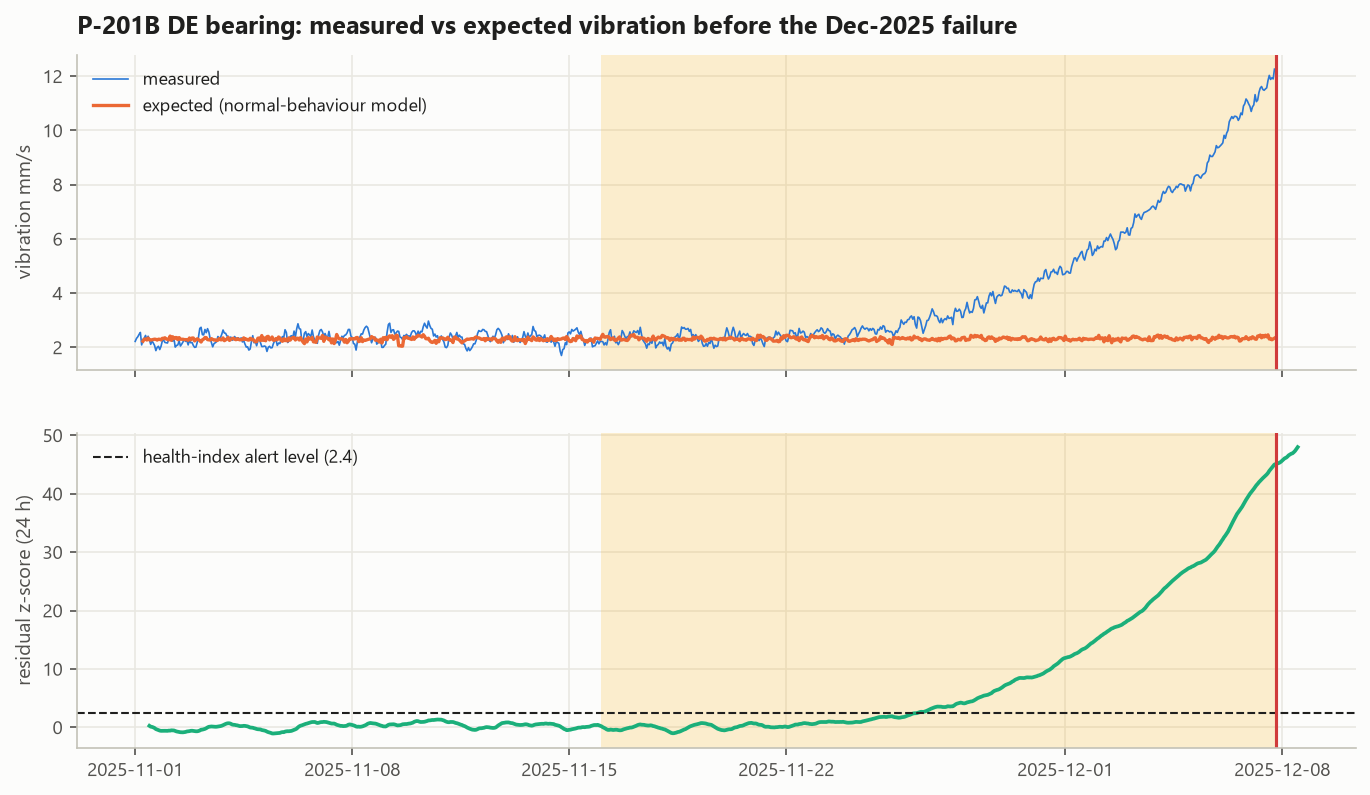

In [12]:
show("fig11_risk_timeline_2025", "fig12_lead_time_model_vs_alarm",
     "fig13_feature_importance", "fig14_normal_behaviour_example")

**Lesson learned:** the supervised classifier works for the pumps (two identical machines, repeated failure modes). For the compressor train (few, very different failure modes) it overfits and is almost always "on". The label-free health index is the right tool there, and it names the sensor that triggered each alert.

## Step 7 – Maintenance action list
Analytics only helps if it ends in a work order: an RCM strategy per failure mode (CBM inspection interval = P-F / 2, RCA for sudden failures), the current watch list with the sensor to check, the 2025 alert log (true or false) and fixes for the bad-actor alarms.

In [13]:
%run ../src/07_maintenance_action_list.py

STEP 7 - Maintenance action list

  WATCH LIST (as of end of data)
        unit status  risk_ratio main_driver_sensor  recommended_action
      P-201B Normal       0.001        PUMP_LT5016 Routine rounds only
      P-201A Normal       0.000        PUMP_PT5015 Routine rounds only
K-101/GT-101 Normal       0.273       GT101_PT2006 Routine rounds only

  STRATEGY BY FAILURE MODE (top 10 by downtime)
asset_id FailureModeCode  downtime_h  min_pf_days              recommended_strategy  inspection_interval_days
   K-101       K101_JBRG         242         12.2 Condition-based maintenance (CBM)                       6.0
  GT-101      GT101_COMB         187          8.8 Condition-based maintenance (CBM)                       4.0
  P-201A       P201A_BRG         159          8.3 Condition-based maintenance (CBM)                       4.0
   K-101        K101_DGS         137         14.9 Condition-based maintenance (CBM)                       7.0
   K-101     K101_THRUST         117         22.7 

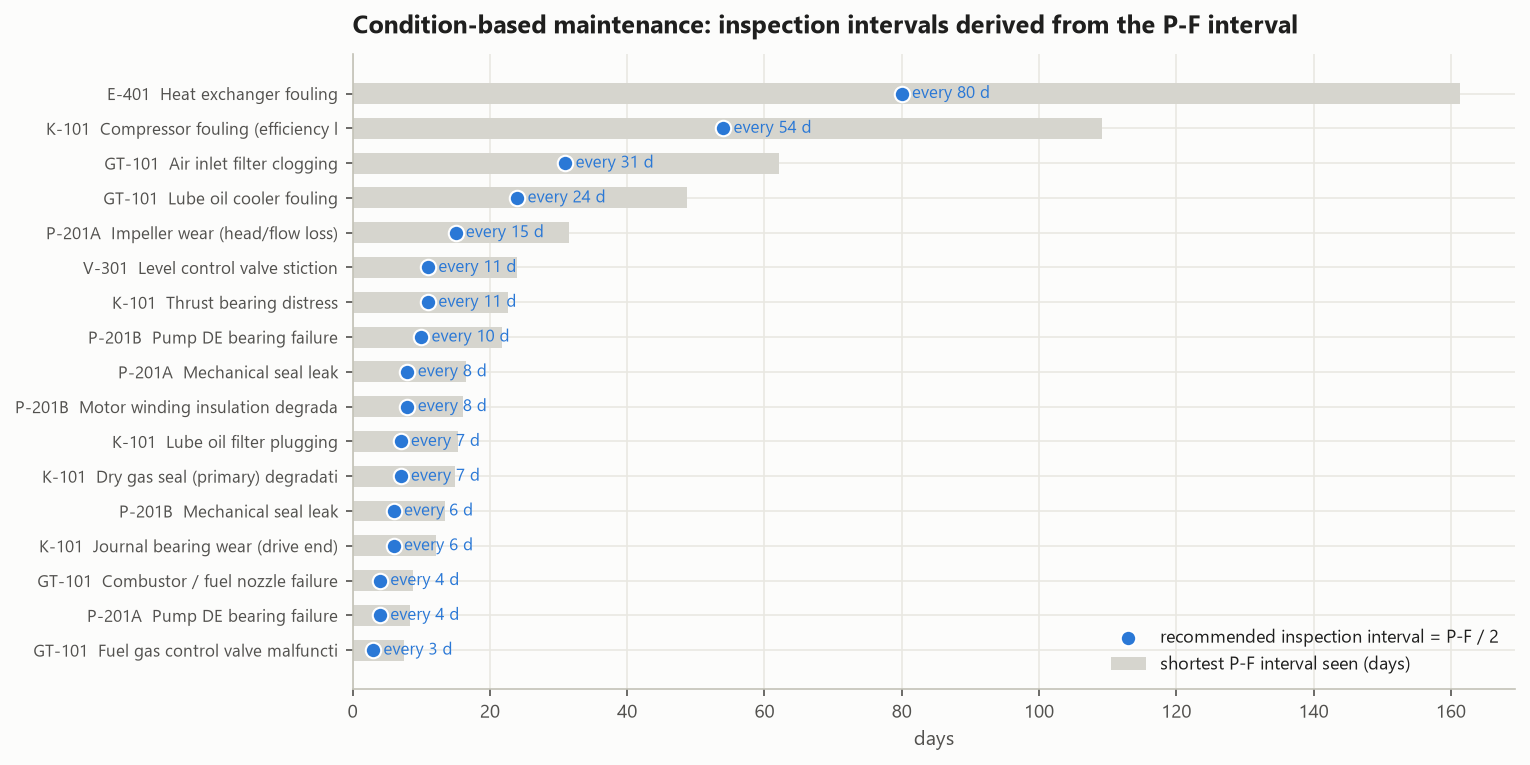

In [14]:
show("fig15_inspection_intervals")

## Step 8 – Export for Power BI and the Excel KPI workbook

In [15]:
%run ../src/08_powerbi_export.py

STEP 8 - Power BI export
  dim_date                       1,096 rows
  dim_asset                         12 rows
  dim_tag                           72 rows
  fact_events                       98 rows
  fact_alarms                      382 rows
  fact_asset_daily               4,384 rows
  fact_sensor_daily             73,361 rows
  fact_health_daily              2,149 rows
  kpi_reliability                    4 rows
  kpi_weibull                        2 rows
  kpi_model_metrics                  6 rows
  kpi_model_event_detection         10 rows
  kpi_feature_importance           102 rows
  kpi_data_quality                  67 rows
  kpi_warning_time                  16 rows
  maint_watch_list                   3 rows
  maint_strategy                    24 rows
  maint_alert_log_2025              19 rows
  maint_alarm_actions               10 rows
  Excel workbook: C:\Users\irace\OneDrive\Documentos\GitHub\OGP1_project_A\Projecto_1\reports\OGP1_Reliability_KPI_Summary.xlsx


## Conclusions
1. 94 % of unplanned downtime came from progressive failures, which can be predicted.
2. DCS alarms warned a median of ~4 days ahead; the models warned a median of 11 days ahead on unseen 2025 data and caught 9 of 10 failures.
3. 17 of 24 failure modes suit condition-based maintenance with inspection intervals of 3–80 days; 7 sudden modes need root-cause analysis.
4. Recommended actions: health-index watch list for K-101/GT-101, condition-based maintenance for pump bearings and seals, alarm rationalisation of the top-10 bad actors, and an RCA of K-101 spurious trips.